# 02 · Does subscription demand tell you anything about IPO returns?

Four questions, each answered separately for mainboard and SME IPOs listed on NSE:

1. **Listing day.** Does subscription demand predict the listing-day gain?
2. **Who is bidding.** Is institutional (QIB) demand a stronger signal than retail or NII (high-net-worth) demand?
3. **After listing.** Do listing pops persist or fade over the following year?
4. **Market conditions.** Does the relationship hold in both hot and cold IPO markets?

**Method.** Returns are heavily skewed and SME listing gains are cut off at a ceiling in two periods (see notebook 01), so everything uses medians, ranks and shares rather than means or ordinary regression:
- Spearman rank correlation (ρ) and differences in medians, each with a 95% bootstrap confidence interval (10,000 resamples, fixed seed; `src/stats.py`).
- A confound check: the same correlation within each listing year, and a median (quantile) regression with year, issue-size and sector controls.
- Effects are in percentage points (pp). Many intervals are reported, so the verdict table also shows Bonferroni-adjusted intervals.

**Definitions.**
- `listing_gain_pct`: listing-day open vs issue price.
- `excess_return_1y_pct`: an allottee's return from the issue price one year after listing, minus NIFTY 50 over the same dates.
- `aftermarket_excess_return_1y_pct`: the same for someone who bought at the listing-day close, so it excludes the listing pop.

In [1]:
import sys
import warnings
from functools import partial
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pipeline.py').exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from src.config import SEGMENTS
from src.data import at_listing_ceiling, load_mart
from src.plotting import MUTED, SEGMENT_COLORS, SEGMENT_LABELS, apply_style, percent_axis, save_fig
from src.stats import (
    Estimate,
    bootstrap_median,
    bootstrap_median_diff,
    bootstrap_spearman,
    bootstrap_spearman_diff,
    decile_table,
    stratified_spearman,
    stratified_spearman_group_diff,
)

apply_style()
pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.max_colwidth', 90)

df = load_mart()
SNAPSHOT = df['snapshot_date'].iloc[0]
df['at_ceiling'] = at_listing_ceiling(df)

## 0 · Sample

- **Included:** IPOs with a listing-day price and subscription figures.
- **SME from 2018 only.** Chittorgarh has no SME subscription records for 2016 and most 2017 records have no figures, so the few that do are not representative.
- **Listing gains at a ceiling are kept.** They are ranked at the top and flagged; a median that sits at a ceiling is only a lower bound.

In [2]:
SME_FROM = pd.Timestamp('2018-01-01')
in_sample = (df['has_subscription_figures'] & df['has_listing_price']
             & ((df['segment'] == 'MAINBOARD') | (df['listing_dt'] >= SME_FROM)))
sample = df[in_sample].copy()
for category in ['total', 'qib', 'nii', 'retail']:
    # One SME issue has a QIB multiple of exactly 0; 0.01x keeps it on the log scale at the bottom
    sample[f'log2_{category}'] = np.log2(sample[f'subscription_{category}_x'].clip(lower=0.01))
sample['log2_issue_size'] = np.log2(sample['issue_size_cr'])
sample['sector'] = sample['sector'].fillna('Unknown')
sample['listing_year'] = sample['listing_year'].astype(int)  # every row has one; patsy can't read Int64
seg = {s: sample[sample['segment'] == s] for s in SEGMENTS}

listed = df[df['has_listing_price']]
print('Listed IPOs with a listing price, left out:',
      {s: int((listed['segment'] == s).sum() - len(seg[s])) for s in SEGMENTS})
sample.groupby('segment', observed=True).agg(
    ipos=('ticker', 'size'),
    first_listing=('listing_dt', 'min'),
    last_listing=('listing_dt', 'max'),
    with_qib_figure=('subscription_qib_x', lambda v: int(v.notna().sum())),
    listing_gain_at_ceiling=('at_ceiling', 'sum'),
    with_1y_return=('aftermarket_excess_return_1y_pct', lambda v: int(v.notna().sum())),
).T

Listed IPOs with a listing price, left out: {'MAINBOARD': 2, 'SME': 102}


segment,MAINBOARD,SME
ipos,448,589
first_listing,2016-02-08 00:00:00,2018-01-10 00:00:00
last_listing,2025-12-30 00:00:00,2026-01-02 00:00:00
with_qib_figure,447,311
listing_gain_at_ceiling,0,49
with_1y_return,354,472


In [3]:
# Every headline estimate goes through record(), so the verdict table can list them all and recompute
# each interval at a Bonferroni-adjusted level at the end.
VERDICT = []


def record(question, segment, measure, unit, estimator):
    estimate = estimator()
    VERDICT.append({'question': question, 'segment': segment, 'measure': measure, 'unit': unit,
                    'estimator': estimator, 'estimate': estimate})
    return estimate


def as_row(estimate: Estimate, **labels):
    return {**labels, 'estimate': estimate.estimate, 'ci_low': estimate.ci_low, 'ci_high': estimate.ci_high,
            'n': estimate.n}


def quartiles(values):
    """Equal-count quartiles 1-4 (ties split by row order)"""
    return pd.qcut(values.rank(method='first'), 4, labels=[1, 2, 3, 4])


def times(v):
    return f'{v:.1f}×' if v < 10 else f'{v:.0f}×'

## 1 · Does subscription demand predict the listing-day gain?

IPOs are split into ten equal-count groups by total subscription. The chart shows each decile's median listing gain and middle 50%.

In [4]:
deciles = {s: decile_table(seg[s], 'subscription_total_x', 'listing_gain_pct', q=10, at_ceiling='at_ceiling')
           for s in SEGMENTS}
pd.concat(deciles, names=['segment'])

n  subscription_total_x_min  subscription_total_x_median  \
segment   group                                                              
MAINBOARD 1      45                      0.53                         1.29   
          2      45                      1.82                         2.18   
          3      45                      2.72                         3.59   
          4      44                      5.83                         8.52   
          5      45                     12.50                        17.60   
          6      45                     26.66                        35.48   
          7      44                     45.62                        59.90   
          8      45                     68.49                        79.37   
          9      45                     92.36                       106.23   
          10     45                    133.56                       175.46   
SME       1      59                      0.07                         1.21   
          2      59                      1.47                         1.80   
          3      59                      2.53                         3.88   
          4      59                      5.91                         8.32   
          5      59                     12.27                        18.22   
          6      58                     30.65                        44.37   
          7      59                     67.48                        87.78   
          8      59                    119.22                       174.95   
          9      59                    218.00                       273.50   
          10     59                    369.56                       507.21   

                 subscription_total_x_max  median   q25    q75  \
segment   group                                                  
MAINBOARD 1                          1.82   -1.10 -6.11   2.00   
          2                          2.68    0.00 -8.06   1.94   
          3                          5.57    0.00 -8.07   5.00   
          4                         12.43    4.79 -1.16  11.45   
          5                         26.54    5.00 -0.35  14.25   
          6                         45.46   12.50  2.03  21.27   
          7                         67.87   20.87  5.17  35.97   
          8                         90.55   37.40 17.42  52.54   
          9                        130.44   35.04 21.25  57.52   
          10                       326.49   67.77 38.42  98.18   
SME       1                          1.47    0.98  0.00   2.41   
          2                          2.47    1.75  0.00   4.97   
          3                          5.79    1.67 -0.04   7.56   
          4                         12.26    3.84 -0.05   9.34   
          5                         29.42    9.20  0.00  21.00   
          6                         66.94   11.39  0.61  22.56   
          7                        117.57   30.43 10.34  59.81   
          8                        217.72   41.41 24.57  71.43   
          9                        364.38   90.00 35.49 112.47   
          10                     2,013.64   90.00 90.00 146.38   

                 share_positive  share_at_ceiling  
segment   group                                    
MAINBOARD 1                0.36              0.00  
          2                0.40              0.00  
          3                0.42              0.00  
          4                0.64              0.00  
          5                0.64              0.00  
          6                0.76              0.00  
          7                0.93              0.00  
          8                0.98              0.00  
          9                1.00              0.00  
          10               1.00              0.00  
SME       1                0.69              0.02  
          2                0.63              0.02  
          3                0.58              0.00  
          4                0.64              0.02  
          5     

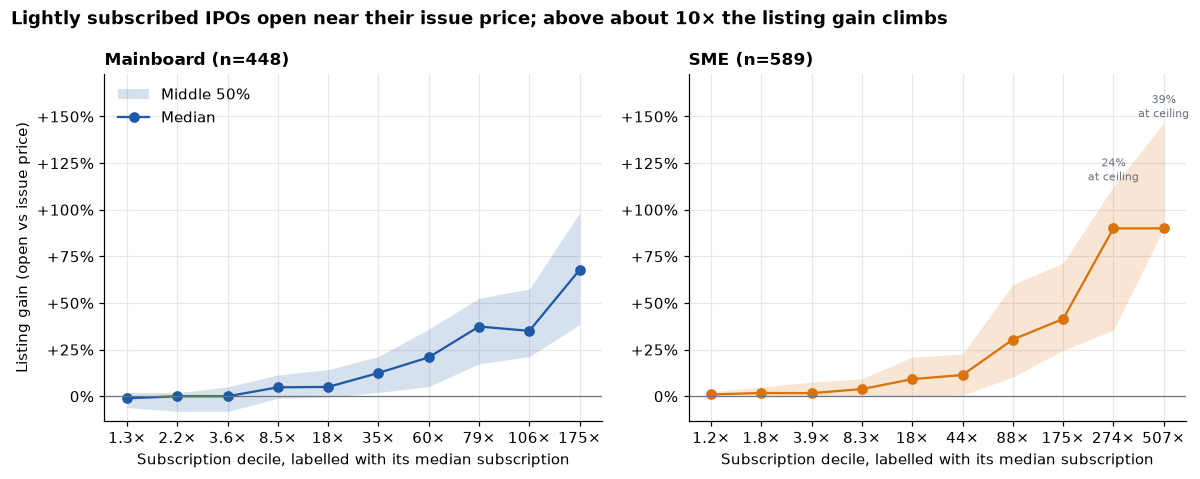

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, s in zip(axes, SEGMENTS):
    t, color = deciles[s], SEGMENT_COLORS[s]
    ax.fill_between(t.index.astype(int), t['q25'], t['q75'], color=color, alpha=0.18, lw=0, label='Middle 50%')
    ax.plot(t.index.astype(int), t['median'], marker='o', color=color, label='Median')
    ax.axhline(0, color=MUTED, lw=0.8)
    for group, row in t.iterrows():
        if row['share_at_ceiling'] >= 0.1:
            ax.annotate(f"{row['share_at_ceiling']:.0%}\nat ceiling", (int(group), row['q75']),
                        textcoords='offset points', xytext=(0, 4), ha='center', fontsize=7.5, color=MUTED)
    ax.set_xticks(t.index.astype(int), [times(v) for v in t['subscription_total_x_median']])
    ax.set_xlabel('Subscription decile, labelled with its median subscription')
    ax.set_title(f"{SEGMENT_LABELS[s]} (n={t['n'].sum()})")
    percent_axis(ax, 'y')
axes[0].set_ylabel('Listing gain (open vs issue price)')
axes[0].legend(loc='upper left')
top = max(t['q75'].max() for t in deciles.values())
for ax in axes:
    ax.set_ylim(min(t['q25'].min() for t in deciles.values()) - 5, top * 1.18)
fig.suptitle('Lightly subscribed IPOs open near their issue price; above about 10× the listing gain climbs',
             x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save_fig(fig, '02_listing_gain_by_subscription_decile')
plt.show()

In [6]:
rows = []
for s in SEGMENTS:
    g = seg[s]
    rho = record('Q1', s, 'ρ: total subscription vs listing gain', 'ρ',
                 partial(bootstrap_spearman, g['subscription_total_x'], g['listing_gain_pct']))
    q = quartiles(g['subscription_total_x'])
    top, bottom = g[q == 4], g[q == 1]
    diff = record('Q1', s, 'Median listing gain: top minus bottom subscription quartile', 'pp',
                  partial(bootstrap_median_diff, top['listing_gain_pct'], bottom['listing_gain_pct']))
    rows.append({
        'segment': s, 'n': len(g), 'rho': str(rho),
        'bottom_quartile_subscription': f"{bottom['subscription_total_x'].max():.1f}× or less",
        'bottom_median_gain': bottom['listing_gain_pct'].median(),
        'bottom_opened_above_issue': (bottom['listing_gain_pct'] > 0).mean(),
        'top_quartile_subscription': f"{top['subscription_total_x'].min():.0f}× or more",
        'top_median_gain': top['listing_gain_pct'].median(),
        'top_opened_above_issue': (top['listing_gain_pct'] > 0).mean(),
        'top_at_ceiling': top['at_ceiling'].mean(),
        'median_diff_pp': str(diff),
    })
pd.DataFrame(rows).set_index('segment').T

segment,MAINBOARD,SME
n,448,589
rho,"+0.76 [+0.72, +0.79] (n=448)","+0.70 [+0.65, +0.74] (n=589)"
bottom_quartile_subscription,3.5× or less,3.9× or less
bottom_median_gain,-1.16,1.03
bottom_opened_above_issue,0.38,0.63
top_quartile_subscription,79× or more,176× or more
top_median_gain,45.33,90.00
top_opened_above_issue,1.00,0.97
top_at_ceiling,0.00,0.25
median_diff_pp,"+46.48 [+38.76, +56.02] (n=224)","+88.97 [+76.79, +89.50] (n=295)"


**Reading.**
- **Yes, strongly, in both segments.** The rank correlation between total subscription and listing gain is ρ = 0.76 [0.72, 0.79] for mainboard and 0.70 [0.65, 0.74] for SME.
- **Weakly subscribed mainboard issues open at about their issue price.**
  - In the bottom three deciles (up to 5.6× subscribed) the median listing gain is −1% to 0%, and only 36–42% open above issue.
  - From there the median climbs: +5% at 6–27×, +21% at 46–68×, +37% at 68–91×.
  - Above 92× every mainboard IPO opened above its issue price.
- **SME has a higher floor but a later take-off.**
  - Even the least-subscribed SME issues usually open a little above issue: 58–69% do in the bottom three deciles, with medians of +1–2%.
  - The median stays below +12% up to about 67× subscription.
  - It reaches +30% only above that, and the ceiling from about 220×.
- **Top vs bottom quartile.**
  - *Mainboard:* the gap in median listing gain is +46 pp [+39, +56]. The bottom quartile (3.5× or less) has a median of −1.2%, with 38% opening above issue. The top quartile (79× or more) has a median of +45%, and all opened above issue.
  - *SME:* the gap is **at least** +89 pp. The top quartile (176× or more) has its median exactly at the +90% ceiling, and 25% of those issues opened at a ceiling. Both the median and the upper end of the interval (+90) are therefore capped, and the true gap is larger.

### 1.1 · Is it just hot years?

Hot years have both heavier subscription and bigger listing gains, so a pooled correlation could simply reflect the market cycle. Two checks:
- **Within-year correlation:** ρ computed inside each listing year (years with at least 10 IPOs), averaged with weights by year size. For mainboard, the same is done within sectors.
- **Median regression:** the change in median listing gain per doubling of subscription, controlling for listing year, issue size and (mainboard) sector. For SME it is also fitted only on the period with no listing ceiling (26 Apr 2018 to 3 Jul 2024).

Regression intervals are the model's asymptotic 95% intervals, not bootstrap intervals.

In [7]:
rows = []
for s in SEGMENTS:
    g = seg[s]
    rows.append(as_row(bootstrap_spearman(g['subscription_total_x'], g['listing_gain_pct']),
                       segment=s, measure='Pooled ρ'))
    rows.append(as_row(record('Q1', s, 'ρ within listing year', 'ρ',
                              partial(stratified_spearman, g, 'subscription_total_x', 'listing_gain_pct',
                                      'listing_year')),
                       segment=s, measure='ρ within listing year'))
    if s == 'MAINBOARD':
        rows.append(as_row(stratified_spearman(g, 'subscription_total_x', 'listing_gain_pct', 'sector'),
                           segment=s, measure='ρ within sector'))
pd.DataFrame(rows).set_index(['segment', 'measure'])

estimate  ci_low  ci_high    n
segment   measure                                              
MAINBOARD Pooled ρ                   0.76    0.72     0.79  448
          ρ within listing year      0.72    0.66     0.76  448
          ρ within sector            0.73    0.66     0.76  444
SME       Pooled ρ                   0.70    0.65     0.74  589
          ρ within listing year      0.60    0.53     0.65  580

In [8]:
def median_slope(data, formula, term):
    """Coefficient on term from a median regression, with the model's 95% interval"""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        fit = smf.quantreg(formula, data).fit(q=0.5, max_iter=10_000)
    low, high = fit.conf_int().loc[term]
    return Estimate(fit.params[term], low, high, int(fit.nobs))


sme = seg['SME']
no_ceiling = sme[(sme['listing_dt'] >= '2018-04-26') & (sme['listing_dt'] < '2024-07-04')]
specs = [
    ('MAINBOARD', 'No controls', seg['MAINBOARD'], 'listing_gain_pct ~ log2_total'),
    ('MAINBOARD', 'Year + issue size', seg['MAINBOARD'],
     'listing_gain_pct ~ log2_total + C(listing_year) + log2_issue_size'),
    ('MAINBOARD', 'Year + issue size + sector', seg['MAINBOARD'],
     'listing_gain_pct ~ log2_total + C(listing_year) + log2_issue_size + C(sector)'),
    ('SME', 'No controls', sme, 'listing_gain_pct ~ log2_total'),
    ('SME', 'Year + issue size', sme, 'listing_gain_pct ~ log2_total + C(listing_year) + log2_issue_size'),
    ('SME', 'Year + issue size, no-ceiling period only', no_ceiling,
     'listing_gain_pct ~ log2_total + C(listing_year) + log2_issue_size'),
]
slopes = pd.DataFrame([as_row(median_slope(data, formula, 'log2_total'), segment=s, controls=label)
                       for s, label, data, formula in specs]).set_index(['segment', 'controls'])
slopes.columns = ['pp_per_doubling', 'ci_low', 'ci_high', 'n']
slopes

pp_per_doubling  ci_low  \
segment   controls                                                             
MAINBOARD No controls                                           6.11    5.34   
          Year + issue size                                     6.83    6.03   
          Year + issue size + sector                            6.75    5.97   
SME       No controls                                           6.82    6.05   
          Year + issue size                                     7.30    6.33   
          Year + issue size, no-ceiling period only             8.84    7.52   

                                                     ci_high    n  
segment   controls                                                 
MAINBOARD No controls                                   6.87  448  
          Year + issue size                             7.63  448  
          Year + issue size + sector                    7.53  448  
SME       No controls                                   7.60  589  
          Year + issue size                             8.27  589  
          Year + issue size, no-ceiling period only    10.16  346

**Reading.**
- **It is not just hot years.**
  - *Mainboard:* within listing years ρ = 0.72 [0.66, 0.76], and within sectors 0.73, against 0.76 pooled. Almost none of the relationship comes from differences between years or sectors.
  - *SME:* within years ρ = 0.60 [0.53, 0.65], against 0.70 pooled. Part of the pooled SME figure reflects the market cycle, because SME's busiest years had both the heaviest subscription and the biggest gains.
- **Size of the effect.** Each doubling of subscription goes with a higher median listing gain:
  - *Mainboard:* +6.8 pp [6.0, 7.6] with year, issue-size and sector controls (+6.1 pp with no controls).
  - *SME:* +7.3 pp [6.3, 8.3], and +8.8 pp [7.5, 10.2] in the period with no listing ceiling. A steeper slope where gains aren't capped is what censoring would predict, although that period also has a different mix of years.
- **The straight line is only a summary.** The decile chart is flat at low subscription and steepest at the top. Going from 1.3× to 3.6× (1.5 doublings) changes the mainboard median by about nothing. Going from 79× to 175× (1.1 doublings) adds about 30 pp.

## 2 · Is QIB demand a stronger signal than retail or NII demand?

Every mainboard issue has a QIB category. For SME, only issues with a QIB figure are used here, and most of those listed in 2023 or later. Each category's multiple is compared with the listing gain. Because the categories move together, the key numbers are the **paired differences** in ρ: both correlations are computed on the same bootstrap resample, so the interval accounts for that. A median regression with all three categories then shows which one still carries information when the others are held fixed.

In [9]:
CATEGORIES = {'Total': 'subscription_total_x', 'QIB': 'subscription_qib_x', 'NII': 'subscription_nii_x',
              'Retail': 'subscription_retail_x'}
q2 = {s: seg[s].dropna(subset=['subscription_qib_x', 'subscription_nii_x', 'subscription_retail_x'])
      for s in SEGMENTS}
print('IPOs used:', {s: len(q2[s]) for s in SEGMENTS})
print('SME issues with a QIB figure by listing year:', q2['SME']['listing_year'].value_counts().sort_index().to_dict())

correlations = pd.DataFrame([
    as_row(bootstrap_spearman(q2[s][column], q2[s]['listing_gain_pct']), segment=s, category=name)
    for s in SEGMENTS for name, column in CATEGORIES.items()
]).set_index(['segment', 'category'])
correlations

IPOs used: {'MAINBOARD': 447, 'SME': 309}
SME issues with a QIB figure by listing year: {2018: 6, 2021: 1, 2022: 9, 2023: 54, 2024: 135, 2025: 103, 2026: 1}


estimate  ci_low  ci_high    n
segment   category                                
MAINBOARD Total         0.75    0.72     0.79  447
          QIB           0.72    0.67     0.76  447
          NII           0.69    0.64     0.73  447
          Retail        0.59    0.53     0.64  447
SME       Total         0.73    0.66     0.78  309
          QIB           0.65    0.58     0.71  309
          NII           0.72    0.65     0.78  309
          Retail        0.72    0.66     0.77  309

In [10]:
rows = []
for s in SEGMENTS:
    g = q2[s]
    for a, b in [('QIB', 'Retail'), ('QIB', 'NII'), ('NII', 'Retail')]:
        estimator = partial(bootstrap_spearman_diff, g[CATEGORIES[a]], g[CATEGORIES[b]], g['listing_gain_pct'])
        estimate = record('Q2', s, f'ρ({a}) minus ρ({b}), vs listing gain', 'ρ', estimator) \
            if a == 'QIB' else estimator()
        rows.append(as_row(estimate, segment=s, difference=f'ρ({a}) − ρ({b})'))
pd.DataFrame(rows).set_index(['segment', 'difference'])

estimate  ci_low  ci_high    n
segment   difference                                        
MAINBOARD ρ(QIB) − ρ(Retail)      0.13    0.07     0.19  447
          ρ(QIB) − ρ(NII)         0.03   -0.01     0.07  447
          ρ(NII) − ρ(Retail)      0.10    0.06     0.15  447
SME       ρ(QIB) − ρ(Retail)     -0.07   -0.12    -0.03  309
          ρ(QIB) − ρ(NII)        -0.07   -0.12    -0.02  309
          ρ(NII) − ρ(Retail)      0.00   -0.04     0.03  309

In [11]:
formula = 'listing_gain_pct ~ log2_qib + log2_nii + log2_retail + C(listing_year) + log2_issue_size'
pd.DataFrame([
    as_row(median_slope(q2[s], formula, f'log2_{c}'), segment=s, category=c.upper() if c != 'retail' else 'Retail')
    for s in SEGMENTS for c in ['qib', 'nii', 'retail']
]).rename(columns={'estimate': 'pp_per_doubling'}).set_index(['segment', 'category'])

pp_per_doubling  ci_low  ci_high    n
segment   category                                       
MAINBOARD QIB                  3.16    1.51     4.81  447
          NII                  1.56    0.13     2.99  447
          Retail               2.06    0.51     3.61  447
SME       QIB                  2.32   -3.41     8.05  309
          NII                  1.59   -4.21     7.39  309
          Retail               5.86   -0.80    12.51  309

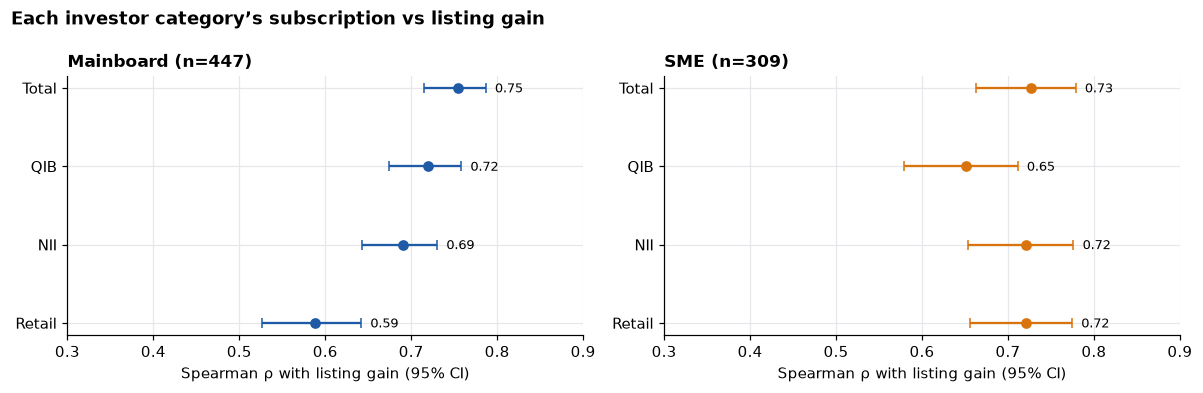

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for ax, s in zip(axes, SEGMENTS):
    t = correlations.loc[s].iloc[::-1]
    y = np.arange(len(t))
    ax.errorbar(t['estimate'], y, xerr=[t['estimate'] - t['ci_low'], t['ci_high'] - t['estimate']], fmt='o',
                color=SEGMENT_COLORS[s], capsize=3)
    for yi, (_, row) in zip(y, t.iterrows()):
        ax.annotate(f"{row['estimate']:.2f}", (row['ci_high'], yi), textcoords='offset points', xytext=(6, -3),
                    fontsize=8.5)
    ax.set_yticks(y, t.index)
    ax.set_title(f"{SEGMENT_LABELS[s]} (n={int(t['n'].iloc[0])})")
    ax.set_xlabel('Spearman ρ with listing gain (95% CI)')
axes[0].set_xlim(0.3, 0.9)
fig.suptitle('Each investor category’s subscription vs listing gain', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save_fig(fig, '02_category_correlations')
plt.show()

The same comparison without a correlation: IPOs split into thirds by QIB subscription and, separately, by retail subscription. Each cell shows the median listing gain and the number of IPOs; cells with fewer than 10 IPOs are greyed out. Reading across a row changes retail demand while QIB demand stays in the same third; reading down a column does the opposite.

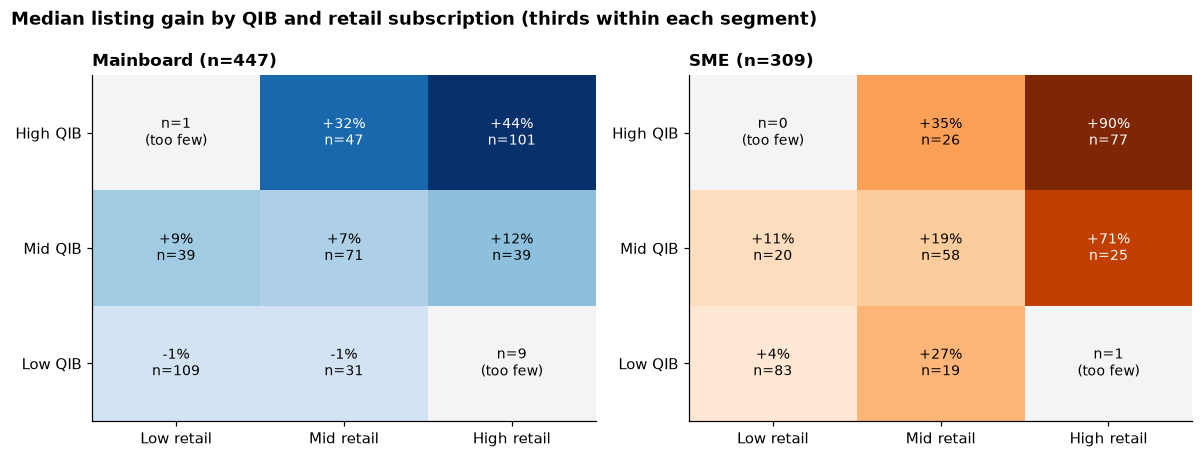

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
labels = ['Low', 'Mid', 'High']
MIN_CELL = 10
for ax, s in zip(axes, SEGMENTS):
    g = q2[s]
    qib_third = pd.qcut(g['subscription_qib_x'].rank(method='first'), 3, labels=labels)
    retail_third = pd.qcut(g['subscription_retail_x'].rank(method='first'), 3, labels=labels)
    grid = g.groupby([qib_third, retail_third], observed=False)['listing_gain_pct'].agg(['median', 'size'])
    counts = grid['size'].unstack().loc[labels[::-1], labels]
    # QIB and retail demand move together, so off-diagonal cells are small; don't colour a median of < 10 IPOs
    medians = grid['median'].unstack().loc[labels[::-1], labels].where(counts >= MIN_CELL)
    values = medians.to_numpy(dtype=float)
    cmap = plt.get_cmap('Blues' if s == 'MAINBOARD' else 'Oranges').copy()
    cmap.set_bad('#f3f4f6')
    ax.imshow(np.ma.masked_invalid(values), cmap=cmap, aspect='auto', vmin=np.nanmin(values) - 10)
    for i in range(3):
        for j in range(3):
            value, n = values[i, j], counts.iat[i, j]
            text = f'{value:+.0f}%\nn={n}' if np.isfinite(value) else f'n={n}\n(too few)'
            ax.text(j, i, text, ha='center', va='center', fontsize=9,
                    color='white' if np.isfinite(value) and value > 0.6 * np.nanmax(values) else 'black')
    ax.set_xticks(range(3), [f'{x} retail' for x in labels])
    ax.set_yticks(range(3), [f'{x} QIB' for x in labels[::-1]])
    ax.grid(False)
    ax.set_title(f"{SEGMENT_LABELS[s]} (n={len(g)})")
fig.suptitle('Median listing gain by QIB and retail subscription (thirds within each segment)', x=0.01,
             ha='left', fontweight='bold')
fig.tight_layout()
save_fig(fig, '02_qib_retail_thirds')
plt.show()

**Reading.**
- **Mainboard: QIB demand is a stronger signal than retail demand, but not clearly stronger than NII demand.**
  - Correlations with listing gain: QIB ρ = 0.72, NII 0.69, retail 0.59.
  - QIB minus retail: +0.13 [+0.07, +0.19]. This still excludes zero after adjustment, at [+0.04, +0.22].
  - QIB minus NII: +0.03 [−0.01, +0.07].
  - **In the thirds chart:** among issues with mid retail demand, the median gain goes from −1% (low QIB) to +7% to +32% (high QIB). Among issues with mid QIB demand, retail only moves it from +9% to +12%.
  - **In the regression:** with year held fixed, each category still adds something. A doubling of QIB demand goes with +3.2 pp [1.5, 4.8], retail with +2.1 pp [0.5, 3.6] and NII with +1.6 pp [0.1, 3.0]. These intervals overlap, so the regression alone doesn't rank the categories.
- **SME: the other way round.**
  - QIB ρ = 0.65, against 0.72 for both NII and retail.
  - QIB minus retail: −0.07 [−0.12, −0.03]. QIB minus NII: −0.07 [−0.12, −0.02]. Both are borderline after adjustment, with upper bounds of −0.00 and +0.00.
  - **In the thirds chart:** among issues with mid QIB demand, retail demand moves the median from +11% to +19% to +71%. Among issues with mid retail demand, QIB demand moves it only between +19% and +35%, and not in order.
  - **In the regression:** no single SME category is distinguishable from zero. The three are strongly correlated and there are only 309 issues.
- **Scope.** The SME comparison covers issues with a QIB figure, and 293 of those 309 listed in 2023 or later. It describes recent SME IPOs. This notebook doesn't test *why* QIB demand says less in SME.

## 3 · Do listing pops persist or fade?

This section uses IPOs whose first year has passed and that have a 1-year return. Two ways to look at the next year:
- **Allottee:** from the issue price. This return includes the listing pop, so it is bound to be higher for big pops.
- **Listing-day buyer:** from the listing-day close (`aftermarket_excess_return_1y_pct`). This is the test of whether a pop carries on or reverses.

Both are measured against NIFTY 50 over the same dates. IPOs are split into quartiles by listing gain and, separately, by subscription.

In [14]:
q3 = {s: seg[s][seg[s]['aftermarket_excess_return_1y_pct'].notna()] for s in SEGMENTS}
due = {s: seg[s][seg[s]['listing_dt'] + pd.DateOffset(years=1) <= SNAPSHOT] for s in SEGMENTS}
print('IPOs used (1 year passed and a 1-year return):', {s: len(q3[s]) for s in SEGMENTS},
      '| 1 year passed but no return (no trade near the date or stopped trading):',
      {s: len(due[s]) - len(q3[s]) for s in SEGMENTS})


def quartile_summary(g, by):
    return g.groupby(quartiles(g[by]), observed=True).agg(
        n=('ticker', 'size'),
        **{f'{by}_median': (by, 'median')},
        listing_gain=('listing_gain_pct', 'median'),
        allottee_excess_1y=('excess_return_1y_pct', 'median'),
        buyer_excess_1y=('aftermarket_excess_return_1y_pct', 'median'),
        buyer_beat_nifty=('aftermarket_excess_return_1y_pct', lambda v: (v > 0).mean()),
    ).rename_axis('quartile')


pd.concat({s: quartile_summary(q3[s], 'listing_gain_pct') for s in SEGMENTS}, names=['segment'])

IPOs used (1 year passed and a 1-year return): {'MAINBOARD': 354, 'SME': 472} | 1 year passed but no return (no trade near the date or stopped trading): {'MAINBOARD': 0, 'SME': 10}


n  listing_gain_pct_median  listing_gain  \
segment   quartile                                               
MAINBOARD 1          89                    -5.56         -5.56   
          2          88                     4.29          4.29   
          3          88                    21.26         21.26   
          4          89                    59.60         59.60   
SME       1         118                     0.00          0.00   
          2         118                     5.85          5.85   
          3         118                    32.20         32.20   
          4         118                    90.00         90.00   

                    allottee_excess_1y  buyer_excess_1y  buyer_beat_nifty  
segment   quartile                                                         
MAINBOARD 1                     -12.04           -10.68              0.39  
          2                       0.08            -7.29              0.47  
          3                      30.84             7.12              0.56  
          4                      45.55           -16.56              0.38  
SME       1                     -35.14           -29.59              0.31  
          2                      -0.62            -9.43              0.42  
          3                      35.34            -1.43              0.49  
          4                      82.69           -21.02              0.41

In [15]:
pd.concat({s: quartile_summary(q3[s], 'subscription_total_x') for s in SEGMENTS}, names=['segment'])

n  subscription_total_x_median  listing_gain  \
segment   quartile                                                   
MAINBOARD 1          89                         1.90         -1.33   
          2          88                        10.02          4.37   
          3          88                        52.23         22.09   
          4          89                       124.74         51.50   
SME       1         118                         1.74          1.29   
          2         118                        15.48          6.08   
          3         118                        91.99         32.84   
          4         118                       351.77         90.00   

                    allottee_excess_1y  buyer_excess_1y  buyer_beat_nifty  
segment   quartile                                                         
MAINBOARD 1                      -7.63            -6.66              0.44  
          2                       9.64            -0.98              0.50  
          3                      24.46           -10.38              0.47  
          4                      41.25           -13.60              0.39  
SME       1                     -15.69           -18.55              0.34  
          2                      -4.16           -15.99              0.43  
          3                      34.15            -8.02              0.47  
          4                      62.02           -22.50              0.38

In [16]:
rows = []
for s in SEGMENTS:
    g = q3[s]
    after = g['aftermarket_excess_return_1y_pct']
    rows.append(as_row(bootstrap_median(g['excess_return_1y_pct']), segment=s,
                       measure='Median allottee 1y excess return, all IPOs (pp)'))
    rows.append(as_row(record('Q3', s, 'Median listing-day buyer’s 1y excess return, all IPOs', 'pp',
                              partial(bootstrap_median, after)),
                       segment=s, measure='Median buyer 1y excess return, all IPOs (pp)'))
    rows.append(as_row(record('Q3', s, 'ρ: listing gain vs listing-day buyer’s 1y excess return', 'ρ',
                              partial(bootstrap_spearman, g['listing_gain_pct'], after)),
                       segment=s, measure='ρ listing gain vs buyer 1y excess'))
    rows.append(as_row(record('Q3', s, 'ρ: total subscription vs listing-day buyer’s 1y excess return', 'ρ',
                              partial(bootstrap_spearman, g['subscription_total_x'], after)),
                       segment=s, measure='ρ subscription vs buyer 1y excess'))
    rows.append(as_row(stratified_spearman(g, 'listing_gain_pct', 'aftermarket_excess_return_1y_pct',
                                           'listing_year'),
                       segment=s, measure='ρ listing gain vs buyer 1y excess, within year'))
    for by, label in [('listing_gain_pct', 'listing-gain'), ('subscription_total_x', 'subscription')]:
        q = quartiles(g[by])
        rows.append(as_row(record('Q3', s, f'Buyer 1y excess return: top minus bottom {label} quartile', 'pp',
                                  partial(bootstrap_median_diff, after[q == 4], after[q == 1])),
                           segment=s, measure=f'Median buyer 1y excess, top − bottom {label} quartile (pp)'))
    rows.append(as_row(bootstrap_spearman(g['listing_gain_pct'], g['excess_return_1y_pct']),
                       segment=s, measure='ρ listing gain vs allottee 1y excess (includes the pop)'))
pd.DataFrame(rows).set_index(['segment', 'measure'])

estimate  \
segment   measure                                                                     
MAINBOARD Median allottee 1y excess return, all IPOs (pp)                     16.41   
          Median buyer 1y excess return, all IPOs (pp)                        -7.93   
          ρ listing gain vs buyer 1y excess                                   -0.01   
          ρ subscription vs buyer 1y excess                                   -0.05   
          ρ listing gain vs buyer 1y excess, within year                       0.04   
          Median buyer 1y excess, top − bottom listing-gain quartile (pp)     -5.88   
          Median buyer 1y excess, top − bottom subscription quartile (pp)     -6.94   
          ρ listing gain vs allottee 1y excess (includes the pop)              0.42   
SME       Median allottee 1y excess return, all IPOs (pp)                     10.52   
          Median buyer 1y excess return, all IPOs (pp)                       -15.84   
          ρ listing gain vs buyer 1y excess                                    0.07   
          ρ subscription vs buyer 1y excess                                   -0.00   
          ρ listing gain vs buyer 1y excess, within year                       0.05   
          Median buyer 1y excess, top − bottom listing-gain quartile (pp)      8.57   
          Median buyer 1y excess, top − bottom subscription quartile (pp)     -3.95   
          ρ listing gain vs allottee 1y excess (includes the pop)              0.45   

                                                                           ci_low  \
segment   measure                                                                   
MAINBOARD Median allottee 1y excess return, all IPOs (pp)                    5.70   
          Median buyer 1y excess return, all IPOs (pp)                     -12.23   
          ρ listing gain vs buyer 1y excess                                 -0.12   
          ρ subscription vs buyer 1y excess                                 -0.15   
          ρ listing gain vs buyer 1y excess, within year                    -0.07   
          Median buyer 1y excess, top − bottom listing-gain quartile (pp)  -19.58   
          Median buyer 1y excess, top − bottom subscription quartile (pp)  -21.23   
          ρ listing gain vs allottee 1y excess (includes the pop)            0.33   
SME       Median allottee 1y excess return, all IPOs (pp)                   -0.47   
          Median buyer 1y excess return, all IPOs (pp)                     -23.16   
          ρ listing gain vs buyer 1y excess                                 -0.03   
          ρ subscription vs buyer 1y excess                                 -0.09   
          ρ listing gain vs buyer 1y excess, within year                    -0.04   
          Median buyer 1y excess, top − bottom listing-gain quartile (pp)   -9.66   
          Median buyer 1y excess, top − bottom subscription quartile (pp)  -19.81   
          ρ listing gain vs allottee 1y excess (includes the pop)            0.37   

                                                                           ci_high  \
segment   measure                                                                    
MAINBOARD Median allottee 1y excess return, all IPOs (pp)                    23.98   
          Median buyer 1y excess return, all IPOs (pp)                       -0.43   
          ρ listing gain vs buyer 1y excess                                   0.10   
          ρ subscription vs buyer 1y excess                                   0.05   
          ρ listing gain vs buyer 1y excess, within year                      0.14   
          Median buyer 1y excess, top − bottom listing-gain quartile (pp)     7.19   
          Median buyer 1y excess, top − bottom subscription quartile (pp)     9.51   
          ρ listing gain vs allottee 1y excess (includes the pop)             0.51   
SME       Median allottee 1y excess return, all IPOs (pp)                    22.41   
          Median buyer 1y exces

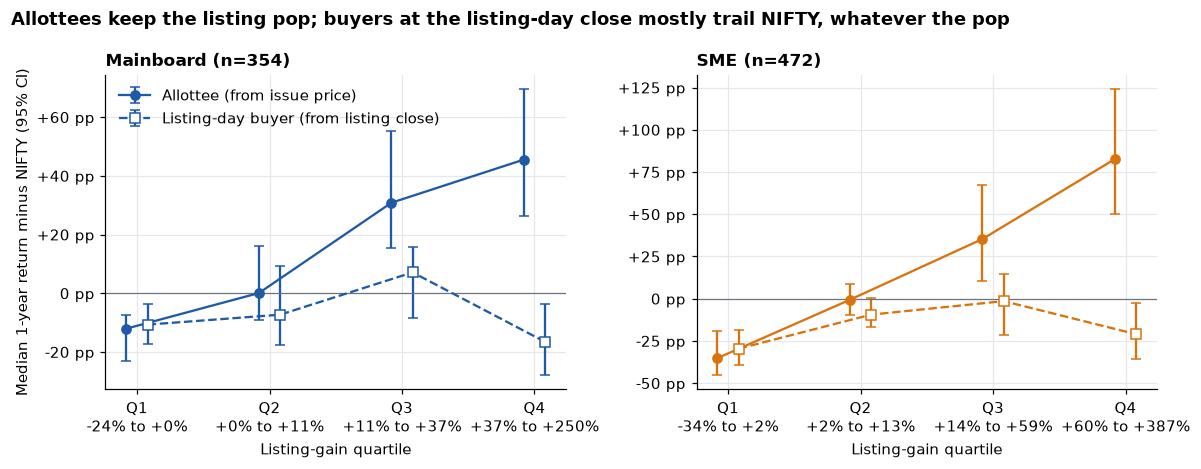

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
views = [('excess_return_1y_pct', 'Allottee (from issue price)', 'o', '-'),
         ('aftermarket_excess_return_1y_pct', 'Listing-day buyer (from listing close)', 's', '--')]
for ax, s in zip(axes, SEGMENTS):
    g, color = q3[s], SEGMENT_COLORS[s]
    q = quartiles(g['listing_gain_pct'])
    ranges = g.groupby(q, observed=True)['listing_gain_pct'].agg(['min', 'max'])
    for offset, (column, label, marker, style) in zip([-0.08, 0.08], views):
        estimates = [bootstrap_median(g.loc[q == k, column]) for k in [1, 2, 3, 4]]
        x = np.arange(1, 5) + offset
        mid = np.array([e.estimate for e in estimates])
        ax.errorbar(x, mid, yerr=[mid - [e.ci_low for e in estimates], [e.ci_high for e in estimates] - mid],
                    marker=marker, linestyle=style, color=color, mfc=color if marker == 'o' else 'white',
                    capsize=3, label=label)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_xticks(range(1, 5), [f'Q{k}\n{ranges.loc[k, "min"]:+.0f}% to {ranges.loc[k, "max"]:+.0f}%'
                               for k in [1, 2, 3, 4]])
    ax.set_xlabel('Listing-gain quartile')
    ax.set_title(f"{SEGMENT_LABELS[s]} (n={len(g)})")
    percent_axis(ax, 'y', suffix=' pp')
axes[0].set_ylabel('Median 1-year return minus NIFTY (95% CI)')
axes[0].legend(loc='upper left')
fig.suptitle('Allottees keep the listing pop; buyers at the listing-day close mostly trail NIFTY, whatever the pop',
             x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save_fig(fig, '02_listing_gain_vs_1y_return')
plt.show()

### 3.1 · Over other horizons

The same rank correlations for listing-day buyers at 1 month, 6 months, 1 year and 3 years. Each horizon uses the IPOs that have reached it, so the 3-year sample only has listings up to early 2023.

In [18]:
rows = []
for s in SEGMENTS:
    for horizon in ['1m', '6m', '1y', '3y']:
        column = f'aftermarket_excess_return_{horizon}_pct'
        g = seg[s][seg[s][column].notna()]
        for by, label in [('listing_gain_pct', 'Listing gain'), ('subscription_total_x', 'Total subscription')]:
            rows.append(as_row(bootstrap_spearman(g[by], g[column]), segment=s, horizon=horizon, predictor=label))
horizons = pd.DataFrame(rows)
horizons.set_index(['segment', 'predictor', 'horizon'])

estimate  ci_low  ci_high    n
segment   predictor          horizon                                
MAINBOARD Listing gain       1m          -0.03   -0.13     0.06  448
          Total subscription 1m          -0.09   -0.19     0.01  448
          Listing gain       6m           0.06   -0.04     0.17  386
          Total subscription 6m          -0.01   -0.11     0.10  386
          Listing gain       1y          -0.01   -0.12     0.10  354
          Total subscription 1y          -0.05   -0.15     0.05  354
          Listing gain       3y          -0.05   -0.20     0.09  207
          Total subscription 3y           0.01   -0.14     0.15  207
SME       Listing gain       1m           0.12    0.03     0.20  589
          Total subscription 1m           0.02   -0.06     0.10  589
          Listing gain       6m           0.07   -0.01     0.16  540
          Total subscription 6m           0.01   -0.07     0.09  540
          Listing gain       1y           0.07   -0.03     0.16  472
          Total subscription 1y          -0.00   -0.09     0.09  472
          Listing gain       3y          -0.00   -0.16     0.15  177
          Total subscription 3y           0.05   -0.10     0.20  177

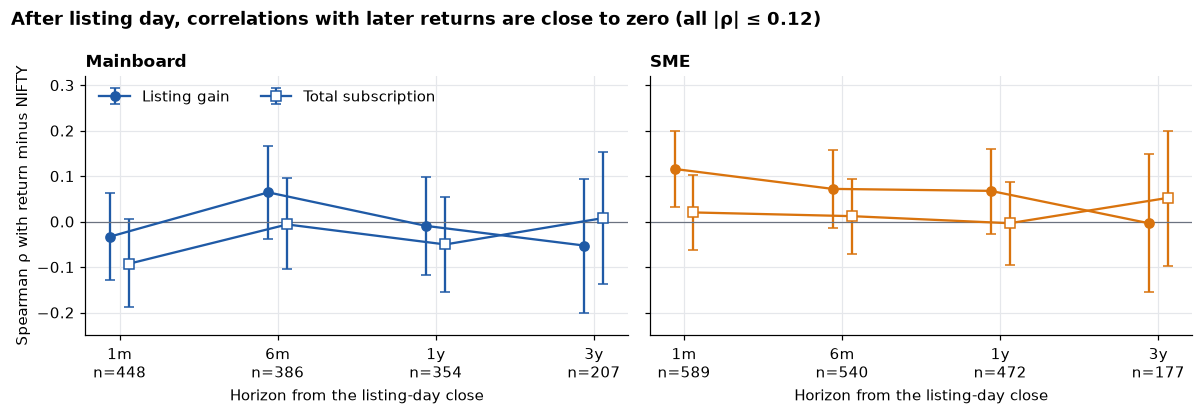

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, s in zip(axes, SEGMENTS):
    for offset, (label, marker) in zip([-0.06, 0.06], [('Listing gain', 'o'), ('Total subscription', 's')]):
        t = horizons[(horizons['segment'] == s) & (horizons['predictor'] == label)]
        x = np.arange(len(t)) + offset
        ax.errorbar(x, t['estimate'], yerr=[t['estimate'] - t['ci_low'], t['ci_high'] - t['estimate']],
                    marker=marker, color=SEGMENT_COLORS[s], mfc=SEGMENT_COLORS[s] if marker == 'o' else 'white',
                    capsize=3, label=label)
    ax.axhline(0, color=MUTED, lw=0.8)
    t = horizons[(horizons['segment'] == s) & (horizons['predictor'] == 'Listing gain')]
    ax.set_xticks(range(len(t)), [f"{h}\nn={n}" for h, n in zip(t['horizon'], t['n'])])
    ax.set_title(SEGMENT_LABELS[s])
    ax.set_xlabel('Horizon from the listing-day close')
axes[0].set_ylabel('Spearman ρ with return minus NIFTY')
axes[0].set_ylim(-0.25, 0.32)
axes[0].legend(loc='upper left', ncols=2)
fig.suptitle(f"After listing day, correlations with later returns are close to zero "
             f"(all |ρ| ≤ {horizons['estimate'].abs().max():.2f})", x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save_fig(fig, '02_fade_by_horizon')
plt.show()

The only interval that excludes zero is SME listing gain vs the 1-month return. One explanation to rule out is the listing ceiling: a stock held down at +90% on its first day might simply catch up over the next weeks. The check below drops listings that opened at a ceiling.

In [20]:
g = seg['SME'].dropna(subset=['aftermarket_excess_return_1m_pct'])
print('SME, listing gain vs 1-month return from listing close:')
print('  all listings:          ', bootstrap_spearman(g['listing_gain_pct'], g['aftermarket_excess_return_1m_pct']))
free = g[~g['at_ceiling']]
print('  excluding at a ceiling:', bootstrap_spearman(free['listing_gain_pct'], free['aftermarket_excess_return_1m_pct']))

SME, listing gain vs 1-month return from listing close:


  all listings:           +0.12 [+0.03, +0.20] (n=589)


  excluding at a ceiling: +0.14 [+0.05, +0.22] (n=540)


**Reading.**
- **Listing pops neither carry on nor reverse.** For someone who buys at the listing-day close:
  - The listing gain has no rank relationship with the next year's return over NIFTY: ρ = −0.01 [−0.12, +0.10] for mainboard and +0.07 [−0.03, +0.16] for SME. It is the same within years.
  - Subscription has none either: −0.05 and −0.00.
  - The top-minus-bottom listing-gain quartile gap is −5.9 pp [−19.6, +7.2] for mainboard and +8.6 pp [−9.7, +28.2] for SME. These intervals are wide: effects of up to about ±20 pp on the median can't be ruled out.
- **The typical listing-day buyer trails NIFTY.** Median 1-year return over NIFTY:
  - *Mainboard:* −7.9 pp [−12.2, −0.4]. This is not significant after adjustment ([−15.4, +3.6]).
  - *SME:* −15.8 pp [−23.2, −9.9], which holds after adjustment.
  - *For allottees* the same medians are +16.4 pp [+5.7, +24.0] (mainboard) and +10.5 pp [−0.5, +22.4] (SME). The gap between allottees and listing-day buyers is the listing pop.
- **Allottees keep the pop.** Their 1-year return is correlated with the listing gain (ρ = 0.42 and 0.45), but only because that return starts from the issue price and so includes the pop.
- **Other horizons.**
  - Every correlation has |ρ| of 0.12 or less.
  - The only interval that excludes zero is SME listing gain vs the 1-month return: 0.12 [0.03, 0.20].
  - It is not the ceiling catching up: without listings at a ceiling it is 0.14. It is also one of 16 intervals in that table, and it has gone by 6 months. At most it is a small, short-lived drift.
- **Survivorship.** Ten SME IPOs that have reached one year have no 1-year return, because there was no trade near the date or the stock stopped trading. Notebook 01 found these are mostly thinly traded stocks rather than failures. At 10 of 482 they can't move the medians much in either direction.

## 4 · Hot and cold IPO years

**Definition.** A **hot year** for a segment is a listing year whose median listing gain is above the median of that segment's yearly medians. Only years with at least 10 IPOs count, which leaves out SME 2020 (8 IPOs) and the one SME listing in January 2026.

**Why this isn't circular.** Correlations are compared *within* years. A rank correlation inside one year doesn't depend on how high that year's gains were overall, so sorting years by their level doesn't build in the answer.

**Why not issuance volume.** The other common definition of a hot market is the number of IPOs. Issuance grew through the decade, so a volume split mostly separates recent years from older ones.

**Caveat.** There are only 10 mainboard and 7 SME years, so this is a thin comparison. The intervals resample IPOs within each year and treat the years as given. They don't reflect how much the answer would change with a different set of hot years.

First, the correlation year by year:

In [21]:
by_year = []
for s in SEGMENTS:
    for year, g in seg[s].groupby('listing_year'):
        if len(g) < 10:
            continue
        by_year.append(as_row(bootstrap_spearman(g['subscription_total_x'], g['listing_gain_pct']),
                              segment=s, year=int(year)) | {'median_listing_gain': g['listing_gain_pct'].median()})
by_year = pd.DataFrame(by_year)
by_year['hot'] = (by_year['median_listing_gain']
                  > by_year.groupby('segment')['median_listing_gain'].transform('median'))
hot_years = {s: sorted(by_year.loc[(by_year['segment'] == s) & by_year['hot'], 'year']) for s in SEGMENTS}
years_used = {s: sorted(by_year.loc[by_year['segment'] == s, 'year']) for s in SEGMENTS}
for s in SEGMENTS:
    print(f"{SEGMENT_LABELS[s]}: hot years {hot_years[s]}; cold years "
          f"{[y for y in years_used[s] if y not in hot_years[s]]}")
by_year.set_index(['segment', 'year'])

Mainboard: hot years [2016, 2020, 2021, 2023, 2024]; cold years [2017, 2018, 2019, 2022, 2025]
SME: hot years [2022, 2023, 2024]; cold years [2018, 2019, 2021, 2025]


estimate  ci_low  ci_high    n  median_listing_gain    hot
segment   year                                                            
MAINBOARD 2016      0.67    0.34     0.87   24                 8.29   True
          2017      0.85    0.69     0.93   34                 4.74  False
          2018      0.64    0.23     0.88   21                 2.70  False
          2019      0.81    0.35     0.98   14                 6.93  False
          2020      0.64    0.21     0.81   13                48.21   True
          2021      0.81    0.72     0.87   61                17.35   True
          2022      0.59    0.30     0.78   38                 3.35  False
          2023      0.76    0.62     0.85   56                16.48   True
          2024      0.72    0.61     0.80   86                17.30   True
          2025      0.68    0.56     0.77  101                 5.36  False
SME       2018      0.42    0.18     0.63   78                 1.38  False
          2019      0.08   -0.56     0.64   14                 1.29  False
          2021      0.25   -0.25     0.66   22                 3.71  False
          2022      0.70    0.52     0.81   54                19.34   True
          2023      0.65    0.53     0.75  117                18.42   True
          2024      0.73    0.65     0.80  178                39.79   True
          2025      0.54    0.37     0.67  117                 5.88  False

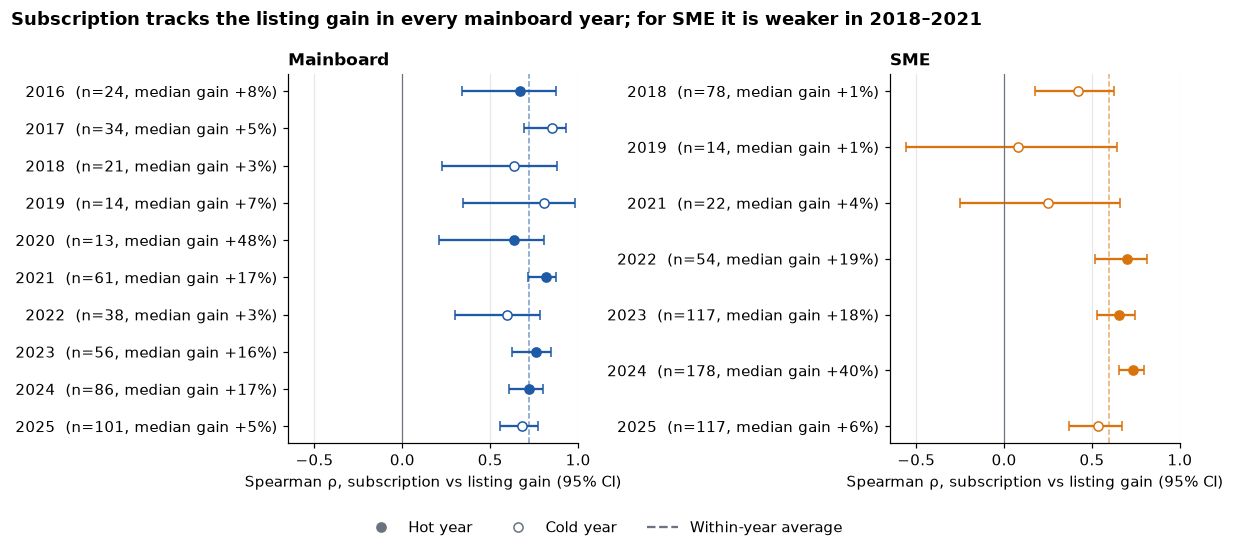

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True)
for ax, s in zip(axes, SEGMENTS):
    t = by_year[by_year['segment'] == s].sort_values('year', ascending=False).reset_index(drop=True)
    color = SEGMENT_COLORS[s]
    for i, row in t.iterrows():
        ax.errorbar(row['estimate'], i, xerr=[[row['estimate'] - row['ci_low']], [row['ci_high'] - row['estimate']]],
                    fmt='o', color=color, mfc=color if row['hot'] else 'white', capsize=3)
    within = stratified_spearman(seg[s], 'subscription_total_x', 'listing_gain_pct', 'listing_year')
    ax.axvline(within.estimate, color=color, lw=1, ls='--', alpha=0.6)
    ax.axvline(0, color=MUTED, lw=0.8)
    ax.set_yticks(t.index, [f"{y}  (n={n}, median gain {m:+.0f}%)"
                            for y, n, m in zip(t['year'], t['n'], t['median_listing_gain'])])
    ax.set_title(SEGMENT_LABELS[s])
    ax.set_xlabel('Spearman ρ, subscription vs listing gain (95% CI)')
    ax.grid(axis='y', visible=False)
axes[0].set_xlim(-0.65, 1)
handles = [plt.Line2D([], [], marker='o', ls='', color=MUTED, label='Hot year'),
           plt.Line2D([], [], marker='o', ls='', color=MUTED, mfc='white', label='Cold year'),
           plt.Line2D([], [], ls='--', color=MUTED, label='Within-year average')]
fig.suptitle('Subscription tracks the listing gain in every mainboard year; for SME it is weaker in 2018–2021',
             x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
fig.legend(handles=handles, loc='upper center', ncols=3, bbox_to_anchor=(0.5, 0.0))
save_fig(fig, '02_correlation_by_year')
plt.show()

In [23]:
rows = []
for s in SEGMENTS:
    g = seg[s][seg[s]['listing_year'].isin(years_used[s])]
    hot, cold = g[g['listing_year'].isin(hot_years[s])], g[~g['listing_year'].isin(hot_years[s])]
    for x, y, label in [('subscription_total_x', 'listing_gain_pct', 'ρ subscription vs listing gain'),
                        ('listing_gain_pct', 'aftermarket_excess_return_1y_pct', 'ρ listing gain vs buyer 1y excess')]:
        diff = record('Q4', s, f'{label}, within year: hot minus cold years', 'ρ',
                      partial(stratified_spearman_group_diff, hot, cold, x, y, 'listing_year'))
        rows.append({'segment': s, 'measure': label,
                     'hot_years': stratified_spearman(hot, x, y, 'listing_year').estimate,
                     'cold_years': stratified_spearman(cold, x, y, 'listing_year').estimate,
                     **as_row(diff, hot_minus_cold='')})
pd.DataFrame(rows).drop(columns='hot_minus_cold').set_index(['segment', 'measure'])

hot_years  cold_years  estimate  \
segment   measure                                                              
MAINBOARD ρ subscription vs listing gain          0.74        0.70      0.05   
          ρ listing gain vs buyer 1y excess       0.04        0.03      0.01   
SME       ρ subscription vs listing gain          0.70        0.44      0.26   
          ρ listing gain vs buyer 1y excess       0.05        0.07     -0.02   

                                             ci_low  ci_high    n  
segment   measure                                                  
MAINBOARD ρ subscription vs listing gain      -0.05     0.15  448  
          ρ listing gain vs buyer 1y excess   -0.23     0.25  347  
SME       ρ subscription vs listing gain       0.13     0.40  580  
          ρ listing gain vs buyer 1y excess   -0.24     0.20  464

**Reading.**
- **Mainboard: it holds in hot and cold years alike.**
  - Within-year ρ is 0.74 in hot years (2016, 2020, 2021, 2023, 2024) and 0.70 in cold years.
  - The difference is +0.05 [−0.05, +0.15].
  - Every single year falls between 0.59 and 0.85.
- **SME: weaker in cold years, but that can't be separated from the early SME market.**
  - Within-year ρ is 0.70 in hot years (2022–2024) and 0.44 in cold years (2018, 2019, 2021, 2025).
  - The difference is +0.26 [+0.13, +0.40], and it stays above zero after adjustment ([+0.06, +0.48]).
  - Three of the four cold years are the early, thin SME market. 2019 and 2021 have only 14 and 22 IPOs, and their intervals include zero.
  - The one recent cold year, 2025, has ρ = 0.54 [0.37, 0.67]: lower than every hot year, but still clearly positive.
- **Fade.** The listing gain says nothing about a listing-day buyer's next year in hot or in cold years. The hot-minus-cold differences are +0.01 and −0.02, with intervals spanning about ±0.2.

## 5 · Verdict

All headline estimates from sections 1–4. Two intervals are shown:
- the ordinary 95% bootstrap interval;
- a Bonferroni-adjusted interval, at a confidence level of 1 − 0.05/k where k is the number of rows. It is the stricter test for anyone reading the table as a set of simultaneous claims.

The adjusted interval relies on the extreme tails of 10,000 resamples, so its bounds are approximate.

In [24]:
k = len(VERDICT)
level = 1 - 0.05 / k
rows = []
for v in VERDICT:
    plain, adjusted = v['estimate'], v['estimator'](ci=level)
    rows.append({
        'question': v['question'], 'segment': v['segment'], 'measure': v['measure'], 'unit': v['unit'],
        'estimate': plain.estimate,
        'ci_95': f'[{plain.ci_low:+.2f}, {plain.ci_high:+.2f}]',
        'ci_adjusted': f'[{adjusted.ci_low:+.2f}, {adjusted.ci_high:+.2f}]',
        'excludes_zero_95': plain.excludes_zero,
        'excludes_zero_adjusted': adjusted.excludes_zero,
        'n': plain.n,
    })
verdict = pd.DataFrame(rows)
print(f'{k} estimates; adjusted confidence level {level:.2%}')
verdict.set_index(['question', 'segment', 'measure'])

24 estimates; adjusted confidence level 99.79%


unit  \
question segment   measure                                                                     
Q1       MAINBOARD ρ: total subscription vs listing gain                                   ρ   
                   Median listing gain: top minus bottom subscription quartile            pp   
         SME       ρ: total subscription vs listing gain                                   ρ   
                   Median listing gain: top minus bottom subscription quartile            pp   
         MAINBOARD ρ within listing year                                                   ρ   
         SME       ρ within listing year                                                   ρ   
Q2       MAINBOARD ρ(QIB) minus ρ(Retail), vs listing gain                                 ρ   
                   ρ(QIB) minus ρ(NII), vs listing gain                                    ρ   
         SME       ρ(QIB) minus ρ(Retail), vs listing gain                                 ρ   
                   ρ(QIB) minus ρ(NII), vs listing gain                                    ρ   
Q3       MAINBOARD Median listing-day buyer’s 1y excess return, all IPOs                  pp   
                   ρ: listing gain vs listing-day buyer’s 1y excess return                 ρ   
                   ρ: total subscription vs listing-day buyer’s 1y excess return           ρ   
                   Buyer 1y excess return: top minus bottom listing-gain quartile         pp   
                   Buyer 1y excess return: top minus bottom subscription quartile         pp   
         SME       Median listing-day buyer’s 1y excess return, all IPOs                  pp   
                   ρ: listing gain vs listing-day buyer’s 1y excess return                 ρ   
                   ρ: total subscription vs listing-day buyer’s 1y excess return           ρ   
                   Buyer 1y excess return: top minus bottom listing-gain quartile         pp   
                   Buyer 1y excess return: top minus bottom subscription quartile         pp   
Q4       MAINBOARD ρ subscription vs listing gain, within year: hot minus cold years       ρ   
                   ρ listing gain vs buyer 1y excess, within year: hot minus cold years    ρ   
         SME       ρ subscription vs listing gain, within year: hot minus cold years       ρ   
                   ρ listing gain vs buyer 1y excess, within year: hot minus cold years    ρ   

                                                                                         estimate  \
question segment   measure                                                                          
Q1       MAINBOARD ρ: total subscription vs listing gain                                     0.76   
                   Median listing gain: top minus bottom subscription quartile              46.48   
         SME       ρ: total subscription vs listing gain                                     0.70   
                   Median listing gain: top minus bottom subscription quartile              88.97   
         MAINBOARD ρ within listing year                                                     0.72   
         SME       ρ within listing year                                                     0.60   
Q2       MAINBOARD ρ(QIB) minus ρ(Retail), vs listing gain                                   0.13   
                   ρ(QIB) minus ρ(NII), vs listing gain                                      0.03   
         SME       ρ(QIB) minus ρ(Retail), vs listing gain                                  -0.07   
                   ρ(QIB) minus ρ(NII), vs listing gain                                     -0.07   
Q3       MAINBOARD Median listing-day buyer’s 1y excess return, all IPOs                    -7.93   
                   ρ: listing gain vs listing-day buyer’s 1y excess return                  -0.01   
                   ρ: total subscription vs listing-day buyer’s 1y excess return            -0.05   
                   Buyer 1y excess return: top minus bottom listing-gain qua

### Answers

**1. Does subscription demand predict the listing-day gain? Yes, strongly, in both segments.**
- Rank correlation 0.76 for mainboard and 0.70 for SME. Within a year it is 0.72 and 0.60.
- Mainboard IPOs subscribed 3.5× or less open at a median of −1%. Those subscribed 79× or more open at a median of +45%, and all of them opened above issue.
- For SME the top-quartile median is capped at the +90% ceiling, so the gap of +89 pp is a lower bound.
- Each doubling of subscription adds about 7 pp to the median listing gain after year and issue-size controls. Most of that gain comes at high subscription levels.

**2. Is QIB demand a stronger signal than retail or NII? For mainboard, stronger than retail; for SME, weaker than both.**
- *Mainboard:* ρ is 0.72 for QIB and 0.59 for retail, a difference of +0.13 [+0.07, +0.19]. QIB and NII are indistinguishable.
- *SME* (issues with a QIB figure, almost all 2023 or later): QIB is the *weakest* of the three, at 0.65 against 0.72, a difference of −0.07 [−0.12, −0.03]. This is borderline after adjustment.

**3. Do listing pops persist or fade? Neither, for anyone buying on listing day.**
- Neither the listing gain nor subscription ranks a listing-day buyer's next-year return over NIFTY (|ρ| ≤ 0.07 at one year).
- The typical listing-day buyer trailed NIFTY by 7.9 pp (mainboard) and 15.8 pp (SME) over that year.
- Allottees kept the pop and beat NIFTY on median (+16.4 pp and +10.5 pp).
- Moderate differences between quartiles (±20 pp) can't be ruled out.

**4. Does it hold in hot and cold IPO years? Mainboard: yes, with no detectable difference. SME: weaker in cold years.**
- Mainboard within-year ρ is 0.74 in hot years and 0.70 in cold years.
- SME within-year ρ is 0.70 in hot years and 0.44 in cold years, a difference of +0.26 [+0.13, +0.40]. Most of the cold SME years are also the early, thin SME market, so the two explanations can't be separated.
- The absence of any link after listing day holds in both kinds of year.

### What this doesn't show
- **Not causation, and not a strategy.**
  - Heavily subscribed issues are the hardest to be allotted, so the listing gains of the top quartile are not what an applicant should expect to earn.
  - Final-day subscription is only partly known when an application has to be made.
  - Any model built on the listing-day result has to account for both.
- **Scope.**
  - NSE listings from 2016 (mainboard) and 2018 (SME) to January 2026.
  - SME QIB results describe 2023 onwards.
  - Returns are price returns without dividends, against the NIFTY 50 price index.
- **Multiple comparisons.** 24 headline intervals are reported. The listing-day results (Q1), mainboard QIB vs retail, the negative SME listing-day buyer median and the SME hot-vs-cold difference all exclude zero at the adjusted level. The mainboard buyer median and the SME QIB comparisons are borderline.